In [74]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
from datetime import datetime

import quimb.tensor as qtn

from qiskit import QuantumCircuit
from tn_simulate_qpt import *
import tn_simulate_qpt

import qiskit as qk
import noise_channels, mpo_noise_channels

seed = 84
np.random.seed(seed)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [75]:
def build_qpt_tn(input_states = 'oc_pauli_eigenstates', 
                 povm = 'oc_pauli_eigenstates',
                 qc_unitary: QuantumCircuit | None = None, 
                 prep_error_mpo: qtn.MatrixProductOperator | None = None,
                 noise_mpo: qtn.MatrixProductOperator | None = None,
                 meas_error_mpo: qtn.MatrixProductOperator | None = None,) -> (qtn.MatrixProductOperator, qtn.TensorNetwork, dict):
    """
    """

    num_qubits = qc_unitary.num_qubits
    
    ################################################################# 
    # PREPARE TOMOGRAPHIC INPUT STATES
    #################################################################
    if isinstance(input_states, str):
        if input_states == 'oc_pauli_eigenstates':
            # Single qubit OC-Pauli eigenstates, 6 of them
            single_qubit_input_states = pauli_eigenstates()
        
        elif input_states == 'sic_states':
            # Single qubit SIC-states, 4 of them
            single_qubit_input_states = sic_tetrahedron_states(type='pauli_symmetric')
        else:
            raise ValueError(f"Input states {input_states} are not defined, only 'oc_pauli_eigenstates' and 'sic_states'. ")
    
    elif isinstance(input_states, (list, np.ndarray)):
        # Manually specified (must be a list or array of density matrices)
        single_qubit_input_states = input_states
    else:
        raise ValueError(f"Type of input state is not valid, only string on list/arrays of density matrices, instead got:\n {type(input_states)}.")
    
    if not ic_condition_check(single_qubit_input_states): # Check that states are IC, that is they sum up to identity up to normalisation factor.
        raise ValueError(f"Input states are not IC, they do not sum up to Identity up to proporionality constant, got:\n {single_qubit_input_states}.")
    
    if len(single_qubit_input_states.shape) == 3: # (num_states, 2, 2): use same input states on each qubit    
        single_qubit_input_states = np.array([single_qubit_input_states]*num_qubits)
    elif len(single_qubit_input_states.shape) == 4: # (num_qubits, num_states, 2, 2): use different input states on different qubits
        pass
    else:
        raise ValueError(f"Weird shape for input state received: {single_qubit_input_states.shape}. Should be an array of (num_qubits, num_states, 2, 2), or (num_states, 2, 2).")
    
    # Multi-qubit MPO fot states
    ptm_input_states = np.array([[rho_to_ptm(s) for s in qubit_states] for qubit_states in single_qubit_input_states])
    ptm_input_states = ptm_input_states.swapaxes(2, 1)
    states_mpo = qtn.MPO_product_operator(ptm_input_states, tags = ['STATES'])

    ################################################################# 
    # PREPARE POVM
    #################################################################
    if isinstance(povm, str):
        if povm == 'oc_pauli_eigenstates':
            single_qubit_povm = pauli_eigenstates()
        else:
            raise ValueError(f"POVM {povm} are not defined, only 'oc_pauli_eigenstates'.")
    elif isinstance(povm, (list, np.ndarray)):
        single_qubit_povm = povm
    else:
        raise ValueError(f"Type of POVM is not valid, only string on list/arrays of effects, instead got:\n {type(povm)}.")
    
    if not ic_condition_check(single_qubit_povm): # Check POVM are IC, that is they sum up to identity up to normalisation factor.
        raise ValueError(f"POVM are not IC, they do not sum up to Identity up to proporionality constant, got:\n {single_qubit_povm}.")
    
    if len(single_qubit_povm.shape) == 3: # (num_states, 2, 2): use same POVM (set of effects) on each qubit      
        single_qubit_povm = np.array([single_qubit_povm]*num_qubits)
    elif len(single_qubit_povm.shape) == 4: # (num_qubits, num_states, 2, 2): use different POVM (set of effects) on each qubit
        pass
    else:
        raise ValueError(f"Weird shape for POVM received: {single_qubit_povm.shape}. Should be an array of (num_qubits, num_povm, 2, 2), or (num_effects, 2, 2).")

    # Multi-qubit MPO fot POVM    
    ptm_povm = np.array([[rho_to_ptm(p) for p in qubit_povm] for qubit_povm in single_qubit_povm])
    povm_mpo = qtn.MPO_product_operator(ptm_povm, tags = ['POVM'])

    ################################################################# 
    # MPO FOR STATE PREPARATION ERROR
    #################################################################
    if prep_error_mpo == None:
        prep_error_mpo = qtn.MPO_identity(num_qubits, phys_dim=4, tags='PREP_ERROR')
    elif isinstance(prep_error_mpo, qtn.MatrixProductOperator):
        prep_error_mpo.add_tag('PREP_ERROR')
    else: 
        raise TypeError(f"prep_error_mpo should be a MPO or None, got {type(prep_error_mpo)}.")

    ################################################################# 
    # MPO FOR THE UNITARY CIRCUIT LAYER
    #################################################################
    if qc_unitary == None:
        qc_mpo = qtn.MPO_identity(num_qubits, phys_dim=4, tags=['UNITARY'])
    elif isinstance(qc_unitary, QuantumCircuit):
        qc_mpo = circuit_to_mpo(qc_unitary, tags=['UNITARY'])
    else: 
        raise TypeError(f"qc_unitary should be a QuantumCircuit or None, got {type(prep_error_mpo)}.")

    ################################################################# 
    # MPO FOR THE NOISE MODEL 
    #################################################################
    if noise_mpo == None:
        noise_mpo = qtn.MPO_identity(num_qubits, phys_dim=4, tags='NOISE')
    elif isinstance(noise_mpo, qtn.MatrixProductOperator):
        noise_mpo.add_tag('NOISE')
    else:
        raise TypeError(f"noise_mpo should be a MPO or None, got {type(prep_error_mpo)}.")

    ################################################################# 
    # MPO FOR THE MEASUREMENT ERROR
    #################################################################
    if meas_error_mpo == None:
        meas_error_mpo = qtn.MPO_identity(num_qubits, phys_dim=4, tags='MEAS_ERROR')
    elif isinstance(meas_error_mpo, qtn.MatrixProductOperator):
        meas_error_mpo.add_tag('MEAS_ERROR')
    else:
        raise TypeError(f"meas_error_mpo should be a MPO or None, got {type(meas_error_mpo)}.")
    
    def combine_tns(mpo_after: qtn.MatrixProductOperator, mpo_before: qtn.MatrixProductOperator) -> qtn.MatrixProductOperator:
        """
        Adapted from 'quimb.tensor.apply_mpo' but without contracting the two MPOs. 
        Combine two MPOs into a single but uncontracted MPO. Acts like matrix multiplication, where MPO_1 is the left matrix and MPO_2 is the right matrix,
        
        MPO = MPO_after (MPO_before) = MPO_after @ MPO_before, acting as
        
        acting on a state from the left as, MPO |MPS_psi>

        In quimb's notation, this would amount to:

         upper_ind
         |
        MPO_after
         |
         lower_ind

         upper_ind
         |
        MPO_before
         |
         lower_ind

        """
        A, B = mpo_after.copy(), mpo_before.copy()
        A.upper_ind_id = B.upper_ind_id
        tmp_ind = qtn.rand_uuid()
        B.upper_ind_id = tmp_ind + '{}'
        A.lower_ind_id = tmp_ind + '{}'
        AB = A | B
        return AB.view_as_(qtn.MatrixProductOperator, upper_ind_id=A.upper_ind_id, lower_ind_id=B.lower_ind_id, cyclic=False)
    
    ################################################################# 
    # CONSTRUCT SIMULATOR
    #################################################################
    qpt_mpo = states_mpo.copy()
    qpt_full_tn = states_mpo.copy()
    for mpo in [prep_error_mpo, qc_mpo, noise_mpo, meas_error_mpo, povm_mpo]:
        qpt_mpo = mpo._apply_mpo(qpt_mpo, compress = False, inplace = False)
        qpt_full_tn = combine_tns(mpo, qpt_full_tn)

    qpt_setup =  {'state_ind_id' : states_mpo.lower_ind_id, 
                  'effect_ind_id': povm_mpo.upper_ind_id, 
                  'states_mpo': states_mpo,
                  'povm_mpo': povm_mpo,
                  'qc_mpo': qc_mpo,
                  'prep_error_mpo': prep_error_mpo,
                  'noise_mpo': noise_mpo,
                  'meas_error_mpo': meas_error_mpo}

    return qpt_mpo, qpt_setup, qpt_full_tn.view_as_(qtn.TensorNetwork1D)

          ┌─────────┐
q_0: ──■──┤ Ry(0.1) ├
     ┌─┴─┐└─────────┘
q_1: ┤ X ├───────────
     └───┘           
q_2: ──■─────────────
     ┌─┴─┐           
q_3: ┤ X ├───────────
     └───┘           


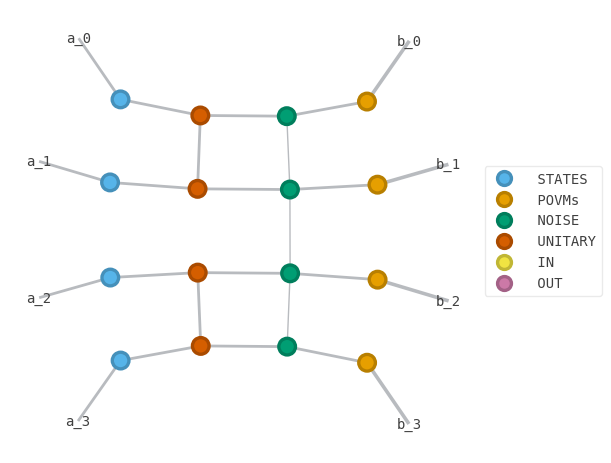

TensorNetwork(tensors=16, indices=32)

In [76]:
######################################
# SELECT THE UNITARY OPERATION
######################################
num_qubits = 4
qc = qk.QuantumCircuit(num_qubits)
qc.cx(0,1)
qc.ry(0.1,0)
qc.cx(2,3)
#qc.cx(4,5)
#qc.cx(6,7)
#qc.cx(8,9)
print(qc)

######################################
# SELECT THE NOISE CHANNEL
######################################
noise_str = 'even_depol1_odd_depol05'
noise_mpo = noise_channels.select_noise_channel(noise_str, num_qubits, tensor_type = 'mpo')

######################################
# BUILD THE QPT MPO
######################################
input_states = 'sic_states'
qpt_mpo, states, povms = tn_simulate_qpt.build_qpt_mpo(qc_unitary = qc, 
                                                       noise_mpo = noise_mpo.copy(), 
                                                       input_states=input_states)

qpt_mpo.draw(color = ['STATES', 'POVMs', 'NOISE', 'UNITARY', 'IN', 'OUT'], show_tags = False)
qpt_mpo

In [77]:
qpt_mpo.mangle_inner_()
qpt_mpo.reindex_({f'a_{q}': f'b{q}' for q in range(10)})
qpt_mpo.reindex_({f'b_{q}': f'k{q}' for q in range(10)})
qpt_mpo

TensorNetwork(tensors=16, indices=32)

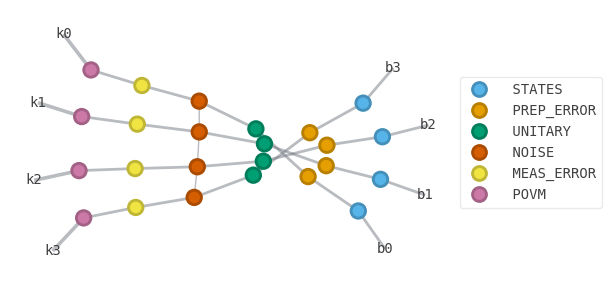

In [78]:
qpt_mpo, qpt_setup, full_tn = build_qpt_tn(input_states = 'sic_states', 
                                           povm = 'oc_pauli_eigenstates', 
                                           qc_unitary = qc, 
                                           noise_mpo = noise_mpo)

full_tn.draw(color = ['STATES', 'PREP_ERROR', 'UNITARY', 'NOISE', 'MEAS_ERROR', 'POVM'], show_tags = False)

In [83]:
psi = qtn.MPS_rand_state(num_qubits, 2, 4, site_ind_id='b{}')
phi = qtn.MPS_rand_state(num_qubits, 2, 6, site_ind_id='k{}')
print((psi | qpt_mpo | phi).contract())
print((psi | full_tn | phi).contract())
print((psi | qpt_mpo | phi).contract())

print(full_tn.distance(qpt_mpo))

for i in range(num_qubits):
    full_tn.contract_(tags=f'I{i}', optimize = 'auto-hq')

full_tn.fuse_multibonds_()
print(full_tn.distance(qpt_mpo))

anna = qpt_mpo.copy()
for i in range(num_qubits):
    anna.contract_(tags=f'I{i}', optimize = 'auto-hq')

print(anna.distance(qpt_mpo))
print(anna.distance(full_tn))

-0.007955138596733372
-0.007955138596733389
-0.007955138596733372
0.0
0.0
0.0
0.0


In [72]:
def simulate_experiments_new(qpt_mpo, qpt_setup, preps_and_meas = None, num_shots: int = 1, 
                             verbose = False, draw_tn = False, joblib_workers = 1):
    """
    """
    def mps_selector(alpha, tags = None, ind = None, state_space = 6):
        """
        Transform a list of integers into a one-hot encoded MPS.
        That is, alpha = [0,2,4,1] becomes an MPS with bond dimension 1
        
         |    |    |    |
        |0>  |2>  |4>  |1>

        where |0> is [1,0,0,0], |2> is [0,0,1,0], etc.
        """
        alpha = np.array(alpha)
        alpha_one_hot = labels_to_tensors(alpha, state_space=state_space)
        in_mps = qtn.MPS_product_state(alpha_one_hot, tags = tags, site_ind_id = ind)
        return in_mps

    def sample_single_shot(preps_and_meas):
        """
        Sample a single-shot from the process tomography experiments, given an input state and a measurement basis.
        """

        input_state, meas_basis = preps_and_meas

        ############################################################################
        # 1. SELECT INITIAL STATE 
        in_state = mps_selector(input_state, state_space=num_states, ind = state_ind_id)
        
        ############################################################################
        # 2. SIMULATE OC-MEASUREMENT BY SAMPLING A POVM OUTCOME FROM THE TENSOR NETWORK GIVEN AN INPUT DATA 
        
        # Initialise to None becuase no qubit has been measured yet
        measured_effect = None

        # Now sample a povm outcome qubit by qubit, by tracing out (num_qubits-1) elements from the TN
        for idx_qub in range(num_qubits):
            
            # Index of qubits to trace out
            qub_to_trace = list(range(idx_qub)) + list(range(idx_qub+1, num_qubits)) 

            # Name of legs and tags to be traced out in the TN
            idx_to_trace = [effect_ind_id.format(idx) for idx in qub_to_trace]
            tag_to_trace = [site_tag.format(idx) for idx in qub_to_trace]

            # Adjust name of legs and tags of the MPS used to trace-out unnmeasured qubits
            all_keys =  [effect_ind_id.format(idx) for idx in range(num_qubits-1)]
            all_tags =  [site_tag.format(idx) for idx in range(num_qubits-1)]
            adjust_idx = dict(zip(all_keys, idx_to_trace))
            adjust_tags = dict(zip(all_tags, tag_to_trace))
            
            # Create the MPS to trace-out unnmeasured qubits
            if measured_effect == None:
                # If no measurements have yet occurred, all qubit but one are traced over by contracting
                # with the identity vector with proper normalization 
                tracing_tensor_data = np.ones(shape=(num_qubits - 1, num_effects)) / povm_normalisation
                measured_effect = []
            else:
                # If measurements have occurred, then create the tensor for tracing given previous measured qubits (starting from qubit 0 to the last)
                # and filling unnmeasured qubits again with the identity vector 
                measured_effect_tn = labels_to_tensors(np.array(measured_effect))
                tracing_arrays = np.ones(shape=(num_qubits-1-idx_qub, num_effects)) / povm_normalisation
                tracing_tensor_data = np.vstack([measured_effect_tn, tracing_arrays])

            # Create MPS
            tr_MPS = qtn.MPS_product_state(tracing_tensor_data, site_ind_id = effect_ind_id, tags = 'TRACING')

            # Reindex the MPS to match indexes to be contracted (i.e. traced-out)
            tr_MPS.reindex(adjust_idx, inplace=True)
            tr_MPS.retag(adjust_tags, inplace=True)
            
            # Perform the contraction and extract probability of measuring OC-POVM on given qubit
            tn_transition_prob = qtn.TensorNetwork([in_state, qpt_mpo, tr_MPS])
            if draw_tn:
                tn_transition_prob.draw(color = ['STATES', 'POVM', 'NOISE', 'UNITARY', 'IN', 'TRACING'], show_tags = False)

            probs = (tn_transition_prob.contract()).data

            try: 
                probs = probs.reshape((num_effects,))
            except:
                raise ValueError(f"Probabilities are not an array of size 6, got {probs.shape} instead.")
            
            if meas_basis == None:
                # Normalise the probabilities (the total sum is higher than 1: for the OC-Pauli POVMs it is 3, as they sum to 3 * Id)
                probs = np.abs(probs / probs.sum())
                # Sample an integer from 0 to num_states with given probabilities
                sampled_effect = np.random.choice(range(num_effects), p=probs)
            else:
                # In this case we want it to be normalised to povm_normalisation, so that otucomes for the same basis (Z, X, Y) sum to 1.
                probs = povm_normalisation * np.abs(probs / probs.sum())

                # Get the measurement basis from the given set (0=Z, 1=X, 2=Y)
                basis = meas_basis[idx_qub] 
                # Sample from POVM effects belonging to the given measurement basis
                sampled_effect = np.random.choice([2*basis, 2*basis + 1], p=probs[2*basis: 2*basis + 2])

            # Append povm outcome to the list of measured qubits
            measured_effect.append(sampled_effect)

        ############################################################################
        # 3. SAVE RESULT IN A DICTIONARY WITH NUM_SHOTS SUB-DICTIONARIES
        
        # Save input state and sampled povmoutcomes as strings
        in_state_str = ''.join(map(str, list(input_state))) 
        out_state_str = ''.join(map(str, measured_effect))
        
        return (in_state_str, out_state_str)

    num_qubits = int(qpt_mpo.L)

    site_tag      = qpt_mpo.site_tag_id
    state_ind_id  = qpt_setup['state_ind_id']  
    effect_ind_id = qpt_setup['effect_ind_id']

    num_states  = qpt_mpo.ind_size(state_ind_id.format(0))  # it is 6 for OC Pauli eigenstates, 4 for SIC-POVMs states
    num_effects = qpt_mpo.ind_size(effect_ind_id.format(0)) # it is 6 for standard measurement in Pauli basis (Z, X, Y basis with two outcomes each)
    
    # @TODO: Add qubit dependent normalisation, assuming it is needed.
    povm_normalisation = [np.round(local_povm.data.squeeze().sum() / np.sqrt(2)) for local_povm in qpt_setup['povm_mpo']]
    if np.isclose(anna[0] - anna, 0).all():
        povm_normalisation = povm_normalisation
    else:
        raise ValueError(f"POVM has different normalization on each qubits, this is not yet implemented in the simulator. POVM normalisation = {povm_normalisation}")

    print(f"Number of input states = {num_states}. Number of effects = {num_effects}, Normalization of the effects = {povm_normalisation}.")

    ############################################################################
    # 0. GENERATE INPUT STATES AND MEASUREMENT BASIS GIVEN STRATEGY
    if preps_and_meas == None:
        input_states = np.random.randint(0, high = num_states, size = (num_shots, num_qubits)) # will use as inputs the 6 OC Pauli eigenstates
        preps_and_meas = [[s, None] for s in input_states] # will measure randomly in one of the Z,X,Y basis

    # Parallelise sampling over multiple cores (joblib_workers = 1 means no parallelisation, = -1 means parallelise over all available cores)
    results = Parallel(n_jobs = joblib_workers)(delayed(sample_single_shot)(p_and_m) for p_and_m in tqdm(preps_and_meas))

    return {f'Exp. {m+1}': {in_state : out_effect} for m, (in_state, out_effect) in enumerate(results)}

In [73]:
num_states = 4
num_effects = 6
shots_per_setting = 1_000
num_settings = 1_000
num_shots = num_settings * shots_per_setting

######################################
# PREPARE EXPERIMENT SETTINGS (input_state, measurement_basis)
######################################
preps_and_meas = [[(np.random.randint(0, num_states, size=num_qubits).tolist(), 
                    np.random.randint(0, 3, size=num_qubits).tolist()), ] * shots_per_setting 
                    for _ in range(num_settings)]
preps_and_meas = tn_simulate_qpt.flatten_list(preps_and_meas)
if len(preps_and_meas) != num_shots: 
    raise ValueError(f"Number of total shots do not match num_settigs ({num_settings}) * shots_per_setting ({shots_per_setting}), got {len(preps_and_meas)} instead.")
print(f"Total number of shots = {num_shots} (number of settings = {num_settings}, shots per setting = {shots_per_setting})")

######################################
# BUILD THE QPT MPO
######################################
input_states = 'sic_states'
povm = 'oc_pauli_eigenstates', 
p_prep = 1e-4
p_meas = 1e-4
noise_str = 'gen_dict_bigger_231127_kyiv_50q'

qpt_mpo, qpt_setup, qpt_tn = build_qpt_tn(input_states = input_states,
                                          povm = povm,
                                          qc_unitary = qc, 
                                          noise_mpo = noise_channels.select_noise_channel(noise_str, num_qubits, tensor_type = 'mpo'),
                                          prep_error_mpo = mpo_noise_channels.dep1loc_layer_mpo(p_prep, num_qubits),
                                          meas_error_mpo = mpo_noise_channels.dep1loc_layer_mpo(p_meas, num_qubits))
        
######################################
# SIMULATE EXPERIMENTS
######################################
experiments = simulate_experiments_new(qpt_mpo, qpt_setup, num_shots = num_shots, preps_and_meas = preps_and_meas, joblib_workers=5)

######################################
# SAVE RESULTS
######################################
res = {'num_shots': num_shots,
       'num_settings': num_settings,
       'shots_per_setting': shots_per_setting,
       'strategy': 'global_repeated',
       'locality': '',
       'states': states.astype('str').tolist(),
       'povms': povms.astype('str').tolist(),
       'qc': qc.qasm(), 
       'noise': noise_str,
       'p_prep': p_prep,
       'p_meas': p_meas,
       'counts': experiments}

save_results = True
if save_results:
    file_folder = 'data/simulated_experiments/'
    file_name = f'cxeven_nq{num_qubits}_{noise_str}_ns{num_shots}_global_repeated_{input_states}'
    today = datetime.today().strftime('%Y-%m-%d')
    with open(file_folder + file_name + '_' + today + '.json', 'w') as file:
        json.dump(res, file, indent = 4)

Total number of shots = 1000000 (number of settings = 1000, shots per setting = 1000)


FileNotFoundError: [Errno 2] No such file or directory: 'gen_dict_bigger_231127_kyiv_50q.txt'